In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

In [2]:
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

data_dir = r"C:\Users\niran\Downloads\Drought prediction_ML\data"

# ------------------------------------------------------------
# Weather columns
# ------------------------------------------------------------

weather_cols = [
    "fips",
    "date",
    "PRECTOT",
    "QV2M",
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "WS10M",
    "score"
]

# ------------------------------------------------------------
# Read datasets
# ------------------------------------------------------------

train = pd.read_csv(
    f"{data_dir}/train_timeseries.csv",
    usecols=weather_cols
)

val = pd.read_csv(
    f"{data_dir}/validation_timeseries.csv",
    usecols=weather_cols
)

test = pd.read_csv(
    f"{data_dir}/test_timeseries.csv",
    usecols=weather_cols
)

soil = pd.read_csv(
    f"{data_dir}/soil_data.csv"
)

print("Weather Shape :")
print(train.shape, val.shape, test.shape)

print("\nSoil Shape :")
print(soil.shape)

# ------------------------------------------------------------
# Preserve split information
# ------------------------------------------------------------

train["split"] = "train"
val["split"] = "validation"
test["split"] = "test"

# ------------------------------------------------------------
# Combine datasets
# ------------------------------------------------------------

full = pd.concat(
    [train, val, test],
    ignore_index=True
)

Weather Shape :
(19300680, 9) (2268840, 9) (2271948, 9)

Soil Shape :
(3109, 32)


In [3]:
train_raw=train.copy()
val_raw=val.copy()
test_raw=test.copy()


In [4]:
# ============================================================
# 4. CHECK DATASETS
# ============================================================

print("\nTRAIN COLUMNS")
print(train_raw.columns.tolist())

print("\nVALIDATION COLUMNS")
print(val_raw.columns.tolist())

print("\nTEST COLUMNS")
print(test_raw.columns.tolist())

print("\nTRAIN DATE RANGE")
print(train_raw["date"].min(), "->", train_raw["date"].max())

print("\nVALIDATION DATE RANGE")
print(val_raw["date"].min(), "->", val_raw["date"].max())

print("\nTEST DATE RANGE")
print(test_raw["date"].min(), "->", test_raw["date"].max())


TRAIN COLUMNS
['fips', 'date', 'PRECTOT', 'QV2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'WS10M', 'score', 'split']

VALIDATION COLUMNS
['fips', 'date', 'PRECTOT', 'QV2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'WS10M', 'score', 'split']

TEST COLUMNS
['fips', 'date', 'PRECTOT', 'QV2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'WS10M', 'score', 'split']

TRAIN DATE RANGE
2000-01-01 -> 2016-12-31

VALIDATION DATE RANGE
2017-01-01 -> 2018-12-31

TEST DATE RANGE
2019-01-01 -> 2020-12-31


In [5]:
weather_all=full.copy()

In [6]:
# ============================================================
# 7. DUPLICATE CHECK
# ============================================================

duplicates = weather_all.duplicated(
    subset=["fips", "date"]
).sum()

print("Duplicate county-date records:", duplicates)

Duplicate county-date records: 0


In [7]:
# ============================================================
# 8. BASIC DATA CLEANING
# ============================================================

# FIPS as string
weather_all["fips"] = (
    weather_all["fips"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(5)
)

# Date
weather_all["date"] = pd.to_datetime(
    weather_all["date"],
    errors="coerce"
)

# Sort chronologically
weather_all = weather_all.sort_values(
    ["fips", "date"]
).reset_index(drop=True)

print("Cleaning completed.")

Cleaning completed.


In [8]:
# ============================================================
# CONVERT DROUGHT SCORE TO INTEGER
# ============================================================

print("Score datatype before:", weather_all["score"].dtype)

weather_all["score"] = pd.to_numeric(
    weather_all["score"],
    errors="coerce"
)

# Remove rows where score could not be converted
weather_all = weather_all.dropna(
    subset=["score"]
).copy()

weather_all["score"] = weather_all["score"].astype(int)

print("Score datatype after :", weather_all["score"].dtype)

print("\nDrought classes:")
print(sorted(weather_all["score"].unique()))

Score datatype before: float64
Score datatype after : int64

Drought classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [10]:
# ============================================================
# 9. SELECT REQUIRED COLUMNS
# ============================================================

weather_cols = [
    "fips",
    "date",
    "PRECTOT",
    "T2M",
    "QV2M",
    "WS10M",
    "score",
    
]

weather_all = weather_all[
    weather_cols
].copy()

print("Shape after column selection:", weather_all.shape)

weather_all.head()

Shape after column selection: (3406368, 7)


,fips,date,PRECTOT,T2M,QV2M,WS10M,score
3,01001,2000-01-04,15.95,11.40,6.42,3.84,1
10,01001,2000-01-11,1.33,11.48,6.63,1.76,2
17,01001,2000-01-18,1.11,14.28,9.53,2.63,2
24,01001,2000-01-25,0.00,-0.78,2.05,3.35,2
31,01001,2000-02-01,0.00,2.06,3.36,2.03,1


In [12]:
# ============================================================
# 10. DATA TYPES
# ============================================================

print(weather_all.dtypes)

fips                  str
date       datetime64[us]
PRECTOT           float64
T2M               float64
QV2M              float64
WS10M             float64
score               int64
dtype: object


In [17]:
# ============================================================
# 11. MISSING VALUE ANALYSIS
# ============================================================

missing = weather_all.isnull().sum()

print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(missing)

MISSING VALUES
fips              0
date              0
PRECTOT           0
T2M               0
QV2M              0
WS10M             0
score      20435100
dtype: int64


In [13]:
# ============================================================
# 12. REMOVE INVALID DATES
# ============================================================

before = len(weather_all)

weather_all = weather_all.dropna(
    subset=["date"]
).copy()

after = len(weather_all)

print("Rows removed:", before - after)

Rows removed: 0


In [15]:
# ============================================================
# DROUGHT CLASS DISTRIBUTION — COUNT + PERCENTAGE
# ============================================================

class_counts = (
    weather_all["score"]
    .value_counts()
    .sort_index()
)

class_percent = (
    class_counts / class_counts.sum() * 100
)

class_distribution = pd.DataFrame({
    "Drought Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage": class_percent.values
})

class_distribution["Percentage"] = (
    class_distribution["Percentage"].round(2)
)

print("=" * 70)
print("DROUGHT CLASS DISTRIBUTION")
print("=" * 70)

display(class_distribution)

DROUGHT CLASS DISTRIBUTION


,Drought Class,Count,Percentage
0,0,2302983,67.61
1,1,507217,14.89
2,2,303718,8.92
3,3,184472,5.42
4,4,85640,2.51
5,5,22338,0.66


In [25]:

print("=" * 70)
print("SOIL DATA")
print("=" * 70)

print("Shape:", soil.shape)

print("\nColumns:")
print(soil.columns.tolist())

soil.head()

SOIL DATA
Shape: (3109, 32)

Columns:
['fips', 'lat', 'lon', 'elevation', 'slope1', 'slope2', 'slope3', 'slope4', 'slope5', 'slope6', 'slope7', 'slope8', 'aspectN', 'aspectE', 'aspectS', 'aspectW', 'aspectUnknown', 'WAT_LAND', 'NVG_LAND', 'URB_LAND', 'GRS_LAND', 'FOR_LAND', 'CULTRF_LAND', 'CULTIR_LAND', 'CULT_LAND', 'SQ1', 'SQ2', 'SQ3', 'SQ4', 'SQ5', 'SQ6', 'SQ7']


,fips,lat,lon,elevation,slope1,slope2,slope3,slope4,slope5,slope6,slope7,slope8,aspectN,aspectE,aspectS,aspectW,aspectUnknown,WAT_LAND,NVG_LAND,URB_LAND,GRS_LAND,FOR_LAND,CULTRF_LAND,CULTIR_LAND,CULT_LAND,SQ1,SQ2,SQ3,SQ4,SQ5,SQ6,SQ7
0,1001,32.536382,-86.644490,63,0.0419,0.2788,0.2984,0.2497,0.1142,0.0170,0.0000,0.0,0.1033,0.1859,0.2003,0.1898,0.3207,0.9974,27.940498,0.2889,2.750274,10.714703,56.293411,1.014811,57.308224,1,1,1,1,1,1,2
1,1005,31.870670,-85.405456,146,0.0158,0.1868,0.5441,0.2424,0.0106,0.0003,0.0000,0.0,0.1415,0.2379,0.2183,0.1997,0.2026,0.0000,0.000000,0.4146,2.225602,22.952839,72.578804,1.828159,74.406960,3,2,1,1,1,1,1
2,1003,30.659218,-87.746067,52,0.0746,0.4370,0.4415,0.0469,0.0000,0.0000,0.0000,0.0,0.1168,0.1386,0.1048,0.1282,0.5116,0.0000,0.000000,3.5010,4.972456,28.685991,59.843639,2.996914,62.840553,3,2,1,2,1,1,1
3,1007,33.015893,-87.127148,93,0.0144,0.1617,0.3714,0.3493,0.0898,0.0134,0.0000,0.0,0.1971,0.1885,0.2279,0.2104,0.1761,0.0000,0.000000,0.2283,8.674664,89.172112,1.916593,0.008330,1.924924,3,2,1,1,1,1,1
4,1009,33.977448,-86.567246,198,0.0050,0.0872,0.2799,0.3576,0.1477,0.1037,0.0189,0.0,0.2569,0.1503,0.2028,0.2978,0.0922,0.0000,0.000000,1.0037,8.606856,88.470047,1.891909,0.027488,1.919397,3,2,1,1,1,1,1


         Count  Percentage
score                     
0      2302983       67.61
1       507217       14.89
2       303718        8.92
3       184472        5.42
4        85640        2.51
5        22338        0.66


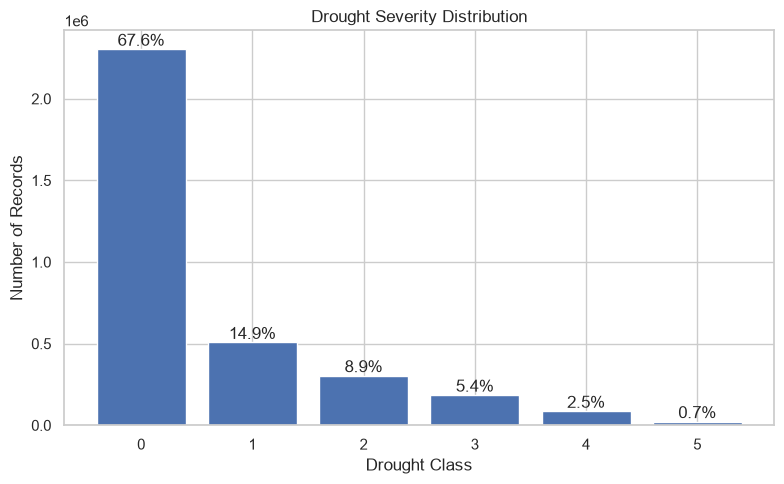

In [16]:
class_counts = (
    weather_all["score"]
    .value_counts()
    .sort_index()
)

class_percent = (
    class_counts / class_counts.sum() * 100
)

distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent.round(2)
})

print(distribution)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    distribution.index.astype(str),
    distribution["Count"]
)

plt.title("Drought Severity Distribution")
plt.xlabel("Drought Class")
plt.ylabel("Number of Records")

# Show percentages above bars
for bar, pct in zip(bars, distribution["Percentage"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# 15. CLEAN SOIL FIPS
# ============================================================

soil["fips"] = (
    soil["fips"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(5)
)

print("Soil FIPS cleaned.")

Soil FIPS cleaned.


In [18]:
# ============================================================
# 16. CHECK SOIL DUPLICATES
# ============================================================

soil_duplicates = soil["fips"].duplicated().sum()

print(
    "Duplicate soil county records:",
    soil_duplicates
)

Duplicate soil county records: 0


In [19]:
# ============================================================
# 16. CHECK SOIL DUPLICATES
# ============================================================

soil_duplicates = soil["fips"].duplicated().sum()

print(
    "Duplicate soil county records:",
    soil_duplicates
)

Duplicate soil county records: 0


In [20]:
# ============================================================
# 18. MERGE WEATHER + SOIL
# ============================================================

combined_df = weather_all.merge(
    soil,
    on="fips",
    how="left"
)

print("=" * 70)
print("COMBINED WEATHER + SOIL DATA")
print("=" * 70)

print("Shape:", combined_df.shape)

COMBINED WEATHER + SOIL DATA
Shape: (3406368, 38)


In [21]:
# ============================================================
# 18. MERGE WEATHER + SOIL
# ============================================================

combined_df = weather_all.merge(
    soil,
    on="fips",
    how="left"
)

print("=" * 70)
print("COMBINED WEATHER + SOIL DATA")
print("=" * 70)

print("Shape:", combined_df.shape)

COMBINED WEATHER + SOIL DATA
Shape: (3406368, 38)
